# Large-scale Synthetic Iris Generation for Few-shot Recognition
## Notebook 11: Identity Consistency Verification

### Objective

A synthetic image is only useful for training if it shows **the identity it was generated for**. This notebook checks that, and rejects the images that fail.

```text
synthetic image of identity P  ->  recognition model  ->  embedding
real images of identity P      ->  recognition model  ->  identity prototype
cosine similarity(embedding, prototype)  >=  threshold   ->  accepted      otherwise  rejected
```

The notebook must:

1. Load the synthetic images and the manifest of Notebook 10.
2. Embed every synthetic image with pretrained recognition models ("judges") and compare it, by cosine similarity, with the real images of its identity.
3. Accept an image only if its similarity reaches a threshold that is **measured on real data** (not guessed).
4. Reject degenerate and identity-inconsistent images.
5. Store the decisions: `accepted/`, `rejected/`, and tables with every score and reason.

### Important boundary of this notebook

This notebook performs **verification only**.

It does **not** generate images (Notebook 10), measure diversity (Notebook 12), or train a recognizer (Notebook 13). No image is modified or deleted: accepted and rejected images are linked (or copied) into separate folders, and the originals stay in `generated_images/`. Only synthetic images of **training** identities are verified.

## 1. Research rationale

### 1.1 The comparison

Every image is mapped to an embedding by a recognizer. An **identity prototype** is the normalised mean embedding of the identity's real `K` support images (the same construction as in Notebooks 07 and 08). The score of a synthetic image is the **cosine similarity** between its embedding and the prototype of the identity it was generated for. The project plan gives the idea ("0.96: good, 0.42: reject"); the notebook measures where the line should be instead of assuming it.

### 1.2 The judges

| Judge | Model | Trained with | Role |
|---|---|---|---|
| `recognizer` | Notebook 07 recognizer (EfficientNet-B0 by default) | ArcFace loss on the real support images of the training identities | **Independent judge. Decides by default.** |
| `latent` | Notebook 08 encoder, identity code `z_id` | ArcFace + triplet (a FaceNet-style metric loss) + reconstruction | Second opinion. **Reported, not decisive by default**: the generator was conditioned on this same latent space, so agreement with it is partly circular. |

CosFace or other embeddings can be added as further judges through the same `Judge` interface. `DECISION_JUDGES` chooses which judges must **all** pass; the others are only reported.

The default recognizer variant is `real_traditional_aug`: the generated images deliberately differ in rotation, illumination, blur, and noise, and a judge that has seen such variations will not reject an image only because it looks different.

### 1.3 Where the threshold comes from

The threshold is calibrated on **real validation identities** (unseen people, real images), exactly like an iris-recognition operating point:

- *genuine* scores: a real probe image against the prototype of its own person,
- *impostor* scores: a real probe image against the prototypes of other people,
- the threshold is the **lowest score at which at most `TARGET_FAR` of the impostor scores are accepted** (default 1%).

So "accepted" means: *at least as identity-consistent as a real image of an unseen person, at a 1% false-accept rate*. `THRESHOLD_MODE = "fixed"` uses a fixed cosine value instead. The optional rule `REQUIRE_NEAREST_IDENTITY` additionally demands that no other training identity is more similar (a 1:N check, stricter, and sensitive to the number of identities).

### 1.4 Other rejections

Images that are almost constant (`pixel_std < MIN_PIXEL_STD`) are rejected as **degenerate** before any similarity is looked at.

### 1.5 What is compared with what

Synthetic images of identity `P` are compared with the prototype built from the **real `train / support` images of `P`**. Nothing else is used to build prototypes. The held-out `train / query` images are **not** used here: the few-shot premise is that only `K` images per identity exist, so the filter must not depend on hidden ones. Validation identities are used for the threshold only; test identities are not touched.

### 1.6 Leakage rules

- Only synthetic images of **training identities** are verified; the notebook asserts that every identity is a `train / support` identity and that all synthetic images are labelled `train`.
- Calibration uses validation people, who are disjoint from the training people (Notebook 06).
- Nothing is written into the real few-shot dataset or `generated_images/`.

### 1.7 Things to keep in mind

- **The judge knows the training identities.** The recognizer was trained on the same `K` real images, so it may be stricter for these identities than for unseen people. If almost everything is rejected, relax `TARGET_FAR`.
- **A filter based on a model selects images that look like the real ones.** It can therefore reduce diversity; Notebook 12 measures diversity on the accepted images.
- **It does not detect copies** of the real images (Notebook 12 does).
- The acceptance rate says as much about the generator as about the threshold: look at the histograms (section 15), not only at the rate.
- **Run `QUICK_TEST = True` first.** **Windows:** no NumPy matrix multiplication is used; PyTorch is imported first.

In [1]:
# ============================================================
# 2. Imports
# ============================================================

import os

# Windows: PyTorch and NumPy can each load their own copy of the OpenMP runtime, and the
# second copy aborts the process at the first NumPy matrix multiplication (the notebook
# kernel "dies"). This must be set BEFORE NumPy / PyTorch are imported.
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import hashlib
import json
import math
import shutil
import time
import warnings
import zlib
from pathlib import Path

# PyTorch is imported first on purpose (avoids DLL-loading conflicts on Windows).
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import torchvision
    from torchvision import models as tv_models
except ImportError as error:
    raise ImportError(
        "Notebook 11 needs PyTorch and torchvision. Install them in the "
        "'Synthetic Iris' environment, e.g. `pip install torch torchvision`."
    ) from error

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
OpenCV version: 5.0.0
NumPy version: 2.4.6
Pandas version: 3.0.5


In [2]:
# ============================================================
# 3. Project paths (inputs)
# ============================================================

NOTEBOOK_DIR = Path.cwd()

if (NOTEBOOK_DIR / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR
elif (NOTEBOOK_DIR.parent / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    raise FileNotFoundError(
        "Could not locate project root. Run this notebook from "
        "the project root or the notebooks directory."
    )

NOTEBOOK06_RESULTS_DIR = PROJECT_ROOT / "results" / "fewshot_dataset"
MANIFEST_LONG_PATH = NOTEBOOK06_RESULTS_DIR / "manifests" / "fewshot_manifest_long.csv"

print("Project root:", PROJECT_ROOT)
print("Notebook 06 few-shot dataset:", NOTEBOOK06_RESULTS_DIR)

Project root: E:\Research\LargeScale_Synthetic_Iris_Generation
Notebook 06 few-shot dataset: E:\Research\LargeScale_Synthetic_Iris_Generation\results\fewshot_dataset


## 4. Configuration

Every setting that can change a result is here and is folded into a **configuration fingerprint**: a finished run is skipped on re-run only if its stored fingerprint matches.

- `QUICK_TEST = True` verifies the few images of Notebook 10's quick test. It reads the **quick-test outputs of Notebooks 07, 08 and 10** (`RECOGNIZER_*` are switched to the quick-test recognizer) and writes to separate folders.
- `GENERATOR_SEED` must match the Notebook 10 / 09 run; `RECOGNIZER_*` and `LATENT_*` choose the judges (their checkpoints must exist for every shot you run).
- `DECISION_JUDGES` are the judges that must **all** pass for an image to be accepted. `JUDGES` are all judges that score every image.
- `THRESHOLD_MODE = "far"` takes the threshold from real validation identities at `TARGET_FAR`; `"fixed"` uses `FIXED_THRESHOLD`.
- `PLACEMENT_MODE`: `"hardlink"` (no extra disk space; falls back to a copy if the file system refuses), `"copy"`, or `"manifest_only"` (tables only, no `accepted/` and `rejected/` folders).

In [3]:
# ============================================================
# 4. Configuration
# ============================================================

QUICK_TEST = False          # True = verify the quick-test images of Notebook 10

# ---- what to run ----
SHOTS_TO_RUN = [1, 2, 3, 5]
TRAIN_DATASETS = ["CASIA-Iris-Thousand"]
GENERATOR_SEED = 42                     # the Notebook 09 / 10 run: diffusion__<K>shot__seed<GENERATOR_SEED>
UPSTREAM_FROM_QUICKTEST = QUICK_TEST    # QUICK_TEST reads the quick-test outputs of Notebooks 07, 08, 10

INPUT_HW = (64, 512)

# ---- judges ----
JUDGES = ["recognizer", "latent"]       # every judge scores every image
DECISION_JUDGES = ["recognizer"]        # judges that must ALL pass for an image to be accepted
RECOGNIZER_BACKBONE = "efficientnet_b0"         # Notebook 07 checkpoint:
RECOGNIZER_VARIANT = "real_traditional_aug"     #   <variant>__<backbone>__<K>shot__seed<RECOGNIZER_SEED>.pt
RECOGNIZER_SEED = 42
LATENT_ENCODER = "cnn"                  # Notebook 08 checkpoint: <encoder>_<mode>__<K>shot__seed<LATENT_SEED>.pt
LATENT_MODE = "vae"
LATENT_SEED = 42

# ---- decision ----
THRESHOLD_MODE = "far"          # "far": calibrate on real validation identities, "fixed": FIXED_THRESHOLD
TARGET_FAR = 0.01               # accepted fraction of impostor scores (mode "far")
FIXED_THRESHOLD = 0.5           # cosine similarity (mode "fixed", and fallback without validation identities)
REQUIRE_NEAREST_IDENTITY = False    # also demand that no other training identity is more similar
MIN_PIXEL_STD = 0.02            # images flatter than this are rejected as degenerate
MIN_ACCEPTED_PER_IDENTITY = 1   # only used to report identities with too few accepted images

# ---- bookkeeping ----
EMBED_BATCH_SIZE = 128
PLACEMENT_MODE = "hardlink"     # "hardlink" | "copy" | "manifest_only"
RESUME = True

if QUICK_TEST:
    SHOTS_TO_RUN = [1, 3]
    RECOGNIZER_BACKBONE = "resnet50"        # the only backbone Notebook 07's quick test trains
    RECOGNIZER_VARIANT = "real_only"        # the only variant Notebook 07's quick test trains
    print("QUICK_TEST is ON: reads the quick-test outputs of Notebooks 07, 08 and 10; separate output folders.")

# ---- sanity checks on the configuration itself ----
assert tuple(INPUT_HW) == (64, 512), "This notebook assumes 64 x 512 iris strips"
assert set(JUDGES) <= {"recognizer", "latent"} and len(JUDGES) >= 1, "JUDGES must be a subset of ['recognizer', 'latent']"
assert len(DECISION_JUDGES) >= 1 and set(DECISION_JUDGES) <= set(JUDGES), "DECISION_JUDGES must be a non-empty subset of JUDGES"
assert THRESHOLD_MODE in {"far", "fixed"}, "THRESHOLD_MODE must be 'far' or 'fixed'"
assert 0.0 < TARGET_FAR < 1.0 and -1.0 <= FIXED_THRESHOLD <= 1.0 and EMBED_BATCH_SIZE >= 1
assert PLACEMENT_MODE in {"hardlink", "copy", "manifest_only"}, "Unknown PLACEMENT_MODE"
assert RECOGNIZER_VARIANT in {"real_only", "real_traditional_aug"}, "Unknown RECOGNIZER_VARIANT"
assert len(SHOTS_TO_RUN) >= 1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Shots:", SHOTS_TO_RUN, "| judges:", JUDGES, "| decided by:", DECISION_JUDGES, "| device:", DEVICE)
print("Threshold:", f"FAR {TARGET_FAR} on real validation identities" if THRESHOLD_MODE == "far" else f"fixed {FIXED_THRESHOLD}")

Shots: [1, 2, 3, 5] | judges: ['recognizer', 'latent'] | decided by: ['recognizer'] | device: cuda
Threshold: FAR 0.01 on real validation identities


In [4]:
# ============================================================
# 4b. Output and upstream locations (depend on QUICK_TEST)
# ============================================================

suffix = "_quicktest" if QUICK_TEST else ""
upstream_suffix = "_quicktest" if UPSTREAM_FROM_QUICKTEST else ""

# upstream (read only)
SYNTHETIC_DIR = PROJECT_ROOT / f"generated_images{upstream_suffix}"
SYNTHETIC_MANIFEST_PATH = PROJECT_ROOT / "results" / f"synthetic_generation{upstream_suffix}" / "synthetic_manifest.csv"
RECOGNIZER_DIR = PROJECT_ROOT / "checkpoints" / f"baseline_recognition{upstream_suffix}"
LATENT_CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints" / f"identity_latent_space{upstream_suffix}"

# outputs
VERIFIED_DIR = PROJECT_ROOT / f"verified_images{suffix}"
ACCEPTED_DIR = VERIFIED_DIR / "accepted"
REJECTED_DIR = VERIFIED_DIR / "rejected"
RESULTS_DIR = PROJECT_ROOT / "results" / f"identity_verification{suffix}"
RUNS_DIR = RESULTS_DIR / "runs"
SCORES_DIR = RESULTS_DIR / "scores"

for directory in [ACCEPTED_DIR, REJECTED_DIR, RESULTS_DIR, RUNS_DIR, SCORES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Synthetic images (read):", SYNTHETIC_DIR)
print("Accepted images:", ACCEPTED_DIR)
print("Rejected images:", REJECTED_DIR)
print("Notebook 11 results:", RESULTS_DIR)

Synthetic images (read): E:\Research\LargeScale_Synthetic_Iris_Generation\generated_images
Accepted images: E:\Research\LargeScale_Synthetic_Iris_Generation\verified_images\accepted
Rejected images: E:\Research\LargeScale_Synthetic_Iris_Generation\verified_images\rejected
Notebook 11 results: E:\Research\LargeScale_Synthetic_Iris_Generation\results\identity_verification


## 5. Utility functions

Real images are read once and cached. Synthetic images are read in chunks and are **never resized**: a wrong-size file stops the notebook, because Notebook 10 guarantees the size. `place_file` links (or copies) an image; it never modifies the original.

In [5]:
# ============================================================
# 5. Utility functions
# ============================================================

def file_digest(path):
    with open(path, "rb") as f:
        return hashlib.blake2b(f.read(), digest_size=16).hexdigest()


def file_signature(path):
    '''Size and modification time: changes whenever the file is rewritten.'''
    stat = Path(path).stat()
    return [int(stat.st_size), int(stat.st_mtime)]


def make_run_id(shot):
    return f"diffusion__{shot}shot__seed{GENERATOR_SEED}"


def recognizer_path(shot):
    return RECOGNIZER_DIR / f"{RECOGNIZER_VARIANT}__{RECOGNIZER_BACKBONE}__{shot}shot__seed{RECOGNIZER_SEED}.pt"


def latent_run_id(shot):
    return f"{LATENT_ENCODER}_{LATENT_MODE}__{shot}shot__seed{LATENT_SEED}"


def latent_checkpoint_path(shot):
    return LATENT_CHECKPOINT_DIR / f"{latent_run_id(shot)}.pt"


IMAGE_CACHE = {}


def read_gray_uint8(path):
    '''Read one real iris texture as a cached uint8 array of shape INPUT_HW.'''
    key = str(path)

    if key not in IMAGE_CACHE:
        image = cv2.imread(key, cv2.IMREAD_GRAYSCALE)

        if image is None:
            raise ValueError(f"Unable to read image: {key}")

        if image.shape != tuple(INPUT_HW):
            image = cv2.resize(image, (INPUT_HW[1], INPUT_HW[0]), interpolation=cv2.INTER_AREA)

        IMAGE_CACHE[key] = image

    return IMAGE_CACHE[key]


def resolve_image_path(row):
    '''Use the Notebook 06 folder tree if present, else the Notebook 05 source file.'''
    in_tree = NOTEBOOK06_RESULTS_DIR / row.relative_path
    if in_tree.exists():
        return in_tree

    source = Path(row.source_path)
    if source.exists():
        return source

    raise FileNotFoundError(f"Image not found in the few-shot tree or at its source: {row.relative_path}")


def load_image_tensor(df):
    '''Stack the real images of a manifest slice into a uint8 tensor [N, H, W].'''
    arrays = [read_gray_uint8(resolve_image_path(row)) for row in df.itertuples(index=False)]
    return torch.from_numpy(np.stack(arrays))


def read_synthetic(path):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if image is None or image.shape != tuple(INPUT_HW):
        raise ValueError(f"Synthetic image is missing, unreadable, or not {INPUT_HW}: {path}")
    return image


def place_file(src, dst, mode):
    '''Link or copy src to dst. Returns "hardlink" or "copy". Never modifies src.'''
    dst = Path(dst)
    dst.parent.mkdir(parents=True, exist_ok=True)

    if dst.exists():
        dst.unlink()

    if mode == "hardlink":
        try:
            os.link(src, dst)
            return "hardlink"
        except OSError:
            pass  # different drive / file system without hard links -> copy

    shutil.copy2(src, dst)
    return "copy"

## 6. Load the datasets and check the upstream outputs

- `fewshot_manifest_long.csv` (Notebook 06) provides the **real** images: the support images that build the identity prototypes, and the validation images that calibrate the threshold.
- `synthetic_manifest.csv` (Notebook 10) lists every synthetic image. Every image gets its own **`verify_id`** (run, identity, index), built here so that IDs are unique across shots.

Before anything starts, the notebook checks that every synthetic image file and every judge checkpoint for the shots you run exists, and that all synthetic images are marked as training images of training identities.

In [6]:
# ============================================================
# 6. Load the datasets
# ============================================================

if not MANIFEST_LONG_PATH.exists():
    raise FileNotFoundError(
        f"Notebook 06 manifest was not found at: {MANIFEST_LONG_PATH}\n"
        "Run 06_FewShot_Dataset_Creation.ipynb first."
    )

if not SYNTHETIC_MANIFEST_PATH.exists():
    raise FileNotFoundError(
        f"Notebook 10 manifest was not found at: {SYNTHETIC_MANIFEST_PATH}\n"
        "Run 10_Synthetic_Image_Generation.ipynb to the end first (it writes the manifest in its last steps)."
    )

long_manifest = pd.read_csv(MANIFEST_LONG_PATH, dtype={"identity": str, "eye": str})
synthetic_manifest = pd.read_csv(SYNTHETIC_MANIFEST_PATH, dtype={"identity": str, "eye": str})

required_real = {"shot", "image_id", "dataset", "class_id", "subject_key", "split", "role", "relative_path", "source_path"}
required_synthetic = {"class_id", "dataset", "identity", "eye", "subject_key", "shot", "split", "synth_index",
                      "bank_index", "relative_path", "generator_run_id"}

for name, table, required in [("Notebook 06", long_manifest, required_real), ("Notebook 10", synthetic_manifest, required_synthetic)]:
    missing = required.difference(table.columns)
    if missing:
        raise ValueError(f"{name} manifest is missing required columns: {sorted(missing)}")

synthetic_manifest["verify_id"] = (synthetic_manifest["generator_run_id"] + "|" + synthetic_manifest["class_id"]
                                   + "|syn_" + synthetic_manifest["synth_index"].astype(int).map("{:03d}".format))
assert synthetic_manifest["verify_id"].is_unique, "verify_id is not unique: the Notebook 10 manifest repeats an image"

available_datasets = sorted(long_manifest["dataset"].unique())
for dataset_name in TRAIN_DATASETS:
    assert dataset_name in available_datasets, (
        f"TRAIN_DATASETS contains '{dataset_name}', which is not in the manifest {available_datasets}")

shots_available = sorted(synthetic_manifest["shot"].unique())
shots_to_run = [k for k in SHOTS_TO_RUN if k in shots_available]
for k in SHOTS_TO_RUN:
    if k not in shots_available:
        print(f"WARNING: {k}-shot has no synthetic images in the Notebook 10 manifest; skipping it.")

if not shots_to_run:
    raise RuntimeError("None of the requested shots exist in the Notebook 10 manifest.")

# upstream files must exist before anything starts
missing_files = []
for shot in shots_to_run:
    if "recognizer" in JUDGES and not recognizer_path(shot).exists():
        missing_files.append(str(recognizer_path(shot)))
    if "latent" in JUDGES and not latent_checkpoint_path(shot).exists():
        missing_files.append(str(latent_checkpoint_path(shot)))
    run_rows = synthetic_manifest[(synthetic_manifest["shot"] == shot) & (synthetic_manifest["generator_run_id"] == make_run_id(shot))]
    if len(run_rows) == 0:
        missing_files.append(f"(no rows for {make_run_id(shot)} in the Notebook 10 manifest)")
    missing_files += [str(SYNTHETIC_DIR / p) for p in run_rows["relative_path"] if not (SYNTHETIC_DIR / p).exists()][:5]

if missing_files:
    raise FileNotFoundError("Upstream files are missing (showing at most a few):\n  " + "\n  ".join(missing_files[:15])
                            + "\nRun Notebooks 07, 08 and 10 first (same shots and seeds; QUICK_TEST reads their quick-test outputs).")

# leakage guards at load time
for shot in shots_to_run:
    rows = synthetic_manifest[(synthetic_manifest["shot"] == shot) & (synthetic_manifest["generator_run_id"] == make_run_id(shot))]
    real = long_manifest[long_manifest["shot"] == shot]
    train_support = real[(real["split"] == "train") & (real["role"] == "support") & (real["dataset"].isin(TRAIN_DATASETS))]
    assert (rows["split"] == "train").all(), f"{shot}-shot: a synthetic image is not labelled as a training image"
    assert set(rows["class_id"]) <= set(train_support["class_id"]), f"{shot}-shot: a synthetic identity is not a training identity"
    held_out = set(real.loc[~real["class_id"].isin(set(train_support["class_id"])), "subject_key"])
    assert not (set(rows["subject_key"]) & held_out), f"{shot}-shot: a synthetic identity shares a person with another split"

print("Datasets in manifest:", available_datasets)
print("Training dataset(s):", TRAIN_DATASETS)
print("Shots that will be run:", shots_to_run)

display(synthetic_manifest[synthetic_manifest["shot"].isin(shots_to_run)]
        .groupby("shot").agg(identities=("class_id", "nunique"), synthetic_images=("verify_id", "count")).reset_index())

# Fingerprint of everything that can change a result.
HYPERPARAMETERS = {
    "train_datasets": TRAIN_DATASETS, "generator_seed": GENERATOR_SEED, "judges": JUDGES, "decision": DECISION_JUDGES,
    "recognizer": [RECOGNIZER_BACKBONE, RECOGNIZER_VARIANT, RECOGNIZER_SEED],
    "latent": [LATENT_ENCODER, LATENT_MODE, LATENT_SEED],
    "rule": [THRESHOLD_MODE, TARGET_FAR, FIXED_THRESHOLD, REQUIRE_NEAREST_IDENTITY, MIN_PIXEL_STD],
    "placement": PLACEMENT_MODE, "upstream_from_quicktest": UPSTREAM_FROM_QUICKTEST,
    "checkpoints": {str(shot): ([file_signature(recognizer_path(shot))] if "recognizer" in JUDGES else [])
                    + ([file_signature(latent_checkpoint_path(shot))] if "latent" in JUDGES else []) for shot in shots_to_run},
    "synthetic_manifest_digest": file_digest(SYNTHETIC_MANIFEST_PATH),
    "manifest_digest": file_digest(MANIFEST_LONG_PATH),
}

CONFIG_HASH = hashlib.blake2b(
    json.dumps(HYPERPARAMETERS, sort_keys=True, default=str).encode("utf-8"), digest_size=6
).hexdigest()

print("Configuration fingerprint:", CONFIG_HASH)

Datasets in manifest: ['CASIA-Iris-Thousand', 'IITD']
Training dataset(s): ['CASIA-Iris-Thousand']
Shots that will be run: [1, 2, 3, 5]


,shot,identities,synthetic_images
0,1,1390,26410
1,2,1384,24912
2,3,1369,23273
3,5,1294,19410


Configuration fingerprint: d3e2d1e007b4


## 7. The judges

- `RecognizerNet` is **copied from Notebook 07** (backbone + 256-d embedding layer); its checkpoint is loaded without downloading any weights.
- `LatentModel` and its parts are **copied from Notebook 08** (via Notebook 09); only its identity code `z_id` is used here.
- A `Judge` turns a batch of images (`uint8`, `[N, 64, 512]`) into **unit-length embeddings**, so that the dot product of two embeddings is their cosine similarity. Both models are used in evaluation mode and are never updated.

In [7]:
# ============================================================
# 7. Judges: Notebook 07 recognizer and Notebook 08 latent model (both copied)
# ============================================================

KNOWN_BACKBONES = {"resnet50": 2048, "efficientnet_b0": 1280, "efficientnet_b3": 1536, "vit_b_16": 768}


class RecognizerNet(nn.Module):
    '''Same structure as Notebook 07's EmbeddingNet (without pretrained-weight loading).'''

    def __init__(self, backbone_name, embedding_dim, vit_input_size):
        super().__init__()
        backbone = getattr(tv_models, backbone_name)(weights=None)

        if backbone_name.startswith("resnet"):
            backbone.fc = nn.Identity()
        elif backbone_name.startswith("efficientnet"):
            backbone.classifier = nn.Identity()
        elif backbone_name.startswith("vit"):
            backbone.heads = nn.Identity()
        else:
            raise ValueError(backbone_name)

        self.backbone = backbone
        self.is_vit = backbone_name.startswith("vit")
        self.vit_input_size = vit_input_size
        self.embed = nn.Sequential(nn.Linear(KNOWN_BACKBONES[backbone_name], embedding_dim), nn.BatchNorm1d(embedding_dim))
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        # x: float [B, 1, H, W] in [0, 1]
        x = x.expand(-1, 3, -1, -1)
        x = (x - self.mean) / self.std
        if self.is_vit:
            x = F.interpolate(x, size=(self.vit_input_size, self.vit_input_size), mode="bilinear", align_corners=False)
        return self.embed(self.backbone(x))


class ConvEncoder(nn.Module):
    def __init__(self, c):
        super().__init__()
        channels = [1, c, 2 * c, 4 * c, 8 * c, 8 * c]
        layers = []
        for i in range(5):                       # 64 x 512 -> 2 x 16
            layers += [nn.Conv2d(channels[i], channels[i + 1], 4, 2, 1, bias=False),
                       nn.BatchNorm2d(channels[i + 1]), nn.LeakyReLU(0.2, inplace=True)]
        self.net = nn.Sequential(*layers)
        self.out_dim = 8 * c * 2 * 16

    def forward(self, x):
        return self.net(x).flatten(1)


class ViTEncoder(nn.Module):
    def __init__(self, dim, depth, heads, patch):
        super().__init__()
        patch = tuple(patch)
        self.patch_embed = nn.Conv2d(1, dim, kernel_size=patch, stride=patch)
        n_tokens = (INPUT_HW[0] // patch[0]) * (INPUT_HW[1] // patch[1])
        self.cls = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos = nn.Parameter(torch.zeros(1, n_tokens + 1, dim))
        nn.init.trunc_normal_(self.cls, std=0.02)
        nn.init.trunc_normal_(self.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(d_model=dim, nhead=heads, dim_feedforward=2 * dim, dropout=0.0,
                                           activation="gelu", batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(layer, num_layers=depth)
        self.norm = nn.LayerNorm(dim)
        self.out_dim = dim

    def forward(self, x):
        tokens = self.patch_embed(x).flatten(2).transpose(1, 2)
        tokens = torch.cat([self.cls.expand(tokens.size(0), -1, -1), tokens], dim=1) + self.pos
        return self.norm(self.blocks(tokens)[:, 0])


class ConvDecoder(nn.Module):
    def __init__(self, latent_dim, c):
        super().__init__()
        self.base = 8 * c
        self.fc = nn.Linear(latent_dim, self.base * 2 * 16)
        channels = [8 * c, 8 * c, 4 * c, 2 * c, c]
        layers = []
        for i in range(4):                       # 2 x 16 -> 32 x 256
            layers += [nn.ConvTranspose2d(channels[i], channels[i + 1], 4, 2, 1, bias=False),
                       nn.BatchNorm2d(channels[i + 1]), nn.ReLU(inplace=True)]
        layers += [nn.ConvTranspose2d(c, 1, 4, 2, 1)]   # -> 64 x 512
        self.net = nn.Sequential(*layers)

    def forward(self, z):
        h = F.relu(self.fc(z)).view(z.size(0), self.base, 2, 16)
        return torch.sigmoid(self.net(h))


class LatentModel(nn.Module):
    '''Encoder -> (z_id, z_app) -> decoder (Notebook 08). Only encode() is used here.'''

    def __init__(self, arch):
        super().__init__()
        self.arch = dict(arch)
        self.mode = arch["mode"]

        if arch["encoder"] == "cnn":
            self.encoder = ConvEncoder(arch["base_channels"])
        else:
            self.encoder = ViTEncoder(arch["vit_dim"], arch["vit_depth"], arch["vit_heads"], arch["vit_patch"])

        features = self.encoder.out_dim
        self.fc_mu_id = nn.Linear(features, arch["id_dim"])
        self.fc_lv_id = nn.Linear(features, arch["id_dim"])
        self.fc_mu_app = nn.Linear(features, arch["app_dim"])
        self.fc_lv_app = nn.Linear(features, arch["app_dim"])
        self.decoder = ConvDecoder(arch["id_dim"] + arch["app_dim"], arch["base_channels"])

    def encode(self, x):
        '''x: float [B, 1, H, W] in [0, 1] -> mu_id, logvar_id, mu_app, logvar_app.'''
        h = self.encoder((x - 0.5) / 0.5)
        return (self.fc_mu_id(h), self.fc_lv_id(h).clamp(-10.0, 5.0),
                self.fc_mu_app(h), self.fc_lv_app(h).clamp(-10.0, 5.0))


def torch_load(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")


def load_recognizer(path, shot):
    checkpoint = torch_load(path)
    assert tuple(checkpoint["input_hw"]) == tuple(INPUT_HW), "the recognizer was trained on a different image size"
    assert int(checkpoint["shot"]) == int(shot), f"the recognizer checkpoint is for {checkpoint['shot']}-shot, not {shot}-shot"

    model = RecognizerNet(checkpoint["backbone"], checkpoint["embedding_dim"], checkpoint["vit_input_size"])
    model.load_state_dict(checkpoint["model_state"])
    return model.to(DEVICE).eval()


def load_latent_model(path, shot):
    checkpoint = torch_load(path)
    assert int(checkpoint["shot"]) == int(shot), f"the latent checkpoint is for {checkpoint['shot']}-shot, not {shot}-shot"

    model = LatentModel(checkpoint["arch"])
    model.load_state_dict(checkpoint["model_state"])
    return model.to(DEVICE).eval()


class Judge:
    '''Turns a uint8 image tensor [N, H, W] into unit-length embeddings [N, D] (cosine similarity = dot product).'''

    def __init__(self, name, encode):
        self.name = name
        self.encode = encode

    @torch.no_grad()
    def embed(self, images_uint8):
        parts = []
        for start in range(0, len(images_uint8), EMBED_BATCH_SIZE):
            x = images_uint8[start:start + EMBED_BATCH_SIZE].to(DEVICE).float().div_(255.0).unsqueeze(1)
            parts.append(F.normalize(self.encode(x).float(), dim=1).cpu())
        return torch.cat(parts)


def load_judges(shot):
    judges = {}

    if "recognizer" in JUDGES:
        recognizer = load_recognizer(recognizer_path(shot), shot)
        judges["recognizer"] = Judge("recognizer", lambda x, m=recognizer: m(x))

    if "latent" in JUDGES:
        latent = load_latent_model(latent_checkpoint_path(shot), shot)
        judges["latent"] = Judge("latent", lambda x, m=latent: m.encode(x)[0])

    return judges

## 8. Prototypes, threshold, and decision

| Function | What it does |
|---|---|
| `class_prototypes` | Normalised mean embedding of each identity's real images |
| `similarity_to_prototypes` | For every image: its similarity to its **own** identity's prototype, and the highest similarity to any **other** identity |
| `far_threshold` | The lowest threshold at which at most `TARGET_FAR` of the impostor scores would be accepted |
| `calibrate_judge` | Genuine and impostor scores of **real validation** identities (gallery = support images, probes = query images), the same protocol as Notebooks 07 and 08 |
| `judge_decision` | `accepted` = similarity at or above the threshold (and, if required, the own identity is the nearest) |

All of them are checked on small hand-computed cases in the next cell.

In [8]:
# ============================================================
# 8. Prototypes, threshold, decision
# ============================================================

def class_prototypes(embeddings, labels):
    '''embeddings: [N, D] unit vectors; labels: N class ids -> (sorted class list, unit prototypes [C, D]).'''
    classes = sorted(set(labels))
    position = {c: i for i, c in enumerate(classes)}
    index = torch.tensor([position[c] for c in labels], dtype=torch.long)
    sums = torch.zeros(len(classes), embeddings.shape[1], dtype=torch.float32)
    sums.index_add_(0, index, embeddings.float())
    return classes, F.normalize(sums, dim=1)


def similarity_to_prototypes(embeddings, own_index, prototypes, chunk=4096):
    '''Per image: similarity to its own identity, and the highest similarity to any other identity.'''
    own_parts, other_parts = [], []

    for start in range(0, len(embeddings), chunk):
        similarity = torch.matmul(embeddings[start:start + chunk], prototypes.t())
        index = own_index[start:start + chunk].unsqueeze(1)
        own_parts.append(similarity.gather(1, index).squeeze(1))
        other_parts.append(similarity.scatter(1, index, -2.0).max(dim=1).values)

    return torch.cat(own_parts), torch.cat(other_parts)


def far_threshold(impostor, far):
    '''Lowest threshold t such that at most a fraction `far` of the impostor scores are >= t.'''
    scores = np.sort(np.asarray(impostor, dtype=np.float64))[::-1]
    allowed = int(math.floor(far * len(scores)))
    if allowed >= len(scores):
        return float(scores[-1])
    return float(np.nextafter(scores[allowed], np.inf))


def judge_decision(own, other, threshold):
    '''own, other: numpy arrays. Returns (passed, too_dissimilar, not_nearest).'''
    too_dissimilar = own < threshold
    not_nearest = ~(own > other)
    passed = ~too_dissimilar
    if REQUIRE_NEAREST_IDENTITY:
        passed = passed & ~not_nearest
    return passed, too_dissimilar, not_nearest


def calibrate_judge(judge, shot):
    '''Genuine / impostor scores of REAL validation identities. Returns None without validation identities.'''
    rows = long_manifest[(long_manifest["shot"] == shot) & (long_manifest["dataset"].isin(TRAIN_DATASETS))
                         & (long_manifest["split"] == "val")]
    support, query = rows[rows["role"] == "support"], rows[rows["role"] == "query"]

    if len(support) == 0 or len(query) == 0:
        return None

    classes, prototypes = class_prototypes(judge.embed(load_image_tensor(support)), support["class_id"].tolist())
    position = {c: i for i, c in enumerate(classes)}
    own_index = torch.tensor([position[c] for c in query["class_id"]], dtype=torch.long)

    similarity = torch.matmul(judge.embed(load_image_tensor(query)), prototypes.t())
    genuine = similarity.gather(1, own_index.unsqueeze(1)).squeeze(1)
    keep = torch.ones_like(similarity, dtype=torch.bool)
    keep.scatter_(1, own_index.unsqueeze(1), False)

    return (genuine.numpy().astype(np.float64), similarity[keep].numpy().astype(np.float64),
            float((similarity.argmax(dim=1) == own_index).float().mean()), len(classes))


# ---- self-tests on hand-computed cases ----
impostor_test = np.arange(1, 11) / 10.0                       # 0.1, 0.2, ..., 1.0
threshold_test = far_threshold(impostor_test, 0.2)            # at most 2 of 10 may be accepted
assert (impostor_test >= threshold_test).sum() == 2 and threshold_test > 0.8, "far_threshold is wrong"
assert (impostor_test >= far_threshold(impostor_test, 0.0)).sum() == 0, "far = 0 must accept no impostor"
assert far_threshold(impostor_test, 0.999) <= 0.1 + 1e-9, "a huge far must accept everything"

unit_vectors = F.normalize(torch.tensor([[1.0, 0.0], [0.8, 0.6], [0.0, 1.0], [0.0, 3.0]]), dim=1)
classes_test, prototypes_test = class_prototypes(unit_vectors, ["a", "a", "b", "b"])
assert classes_test == ["a", "b"] and torch.allclose(prototypes_test.norm(dim=1), torch.ones(2), atol=1e-6)
assert torch.allclose(prototypes_test[1], torch.tensor([0.0, 1.0]), atol=1e-6)
assert torch.allclose(prototypes_test[0], F.normalize(torch.tensor([1.8, 0.6]), dim=0), atol=1e-6)

probe = F.normalize(torch.tensor([[1.0, 0.0], [0.6, 0.8]]), dim=1)
own_test, other_test = similarity_to_prototypes(probe, torch.tensor([0, 0]), torch.tensor([[1.0, 0.0], [0.0, 1.0]]))
assert torch.allclose(own_test, torch.tensor([1.0, 0.6]), atol=1e-6) and torch.allclose(other_test, torch.tensor([0.0, 0.8]), atol=1e-6)

saved_rule = REQUIRE_NEAREST_IDENTITY
REQUIRE_NEAREST_IDENTITY = False
passed_test, low_test, not_nearest_test = judge_decision(own_test.numpy(), other_test.numpy(), 0.5)
assert passed_test.tolist() == [True, True] and not_nearest_test.tolist() == [False, True]
REQUIRE_NEAREST_IDENTITY = True
passed_test, _, _ = judge_decision(own_test.numpy(), other_test.numpy(), 0.5)
assert passed_test.tolist() == [True, False], "the nearest-identity rule must reject the second image"
passed_test, low_test, _ = judge_decision(own_test.numpy(), other_test.numpy(), 0.9)
assert passed_test.tolist() == [True, False] and low_test.tolist() == [False, True]
REQUIRE_NEAREST_IDENTITY = saved_rule

# the copied recognizer must build, run, and return unit-length-able 256-d embeddings (random weights, no download)
probe_net = RecognizerNet(RECOGNIZER_BACKBONE, 256, 224).to(DEVICE).eval()
with torch.no_grad():
    probe_embedding = probe_net(torch.rand(2, 1, *INPUT_HW, device=DEVICE))
assert probe_embedding.shape == (2, 256) and torch.isfinite(probe_embedding).all(), "RecognizerNet is broken"
del probe_net

print("Prototype, threshold, and decision self-tests passed.")

Prototype, threshold, and decision self-tests passed.


## 9. Verifying one shot

`verify_for_run(shot)`:

1. Runs the leakage guards (training identities only, label `train`).
2. Reads the synthetic images in chunks and embeds them with every judge; images that are almost constant are marked **degenerate**.
3. For every judge: builds the identity prototypes from the real `train / support` images, calibrates the threshold on the real validation identities, scores every synthetic image, and records whether it passes.
4. An image is **accepted** only if it is not degenerate and **every judge in `DECISION_JUDGES`** passes. The first failing reason is stored (`degenerate_image`, `low_similarity_<judge>`, `not_nearest_identity_<judge>`).
5. Links (or copies) each image into `accepted/<run>/...` or `rejected/<run>/...`, replacing only the folders of this run.
6. Writes the scores of this shot to `scores/<run>.csv`.

The record of the run also keeps, per judge, the threshold, where it came from, its performance on the real validation identities, and score histograms for the figures.

In [9]:
# ============================================================
# 9. Verify one shot
# ============================================================

HISTOGRAM_EDGES = np.linspace(-1.0, 1.0, 81)


def histogram_counts(values):
    return np.histogram(np.asarray(values, dtype=np.float64), bins=HISTOGRAM_EDGES)[0].astype(int).tolist()


def verify_for_run(shot):
    started = time.time()
    run_id = make_run_id(shot)
    rows = synthetic_manifest[(synthetic_manifest["shot"] == shot) & (synthetic_manifest["generator_run_id"] == run_id)].reset_index(drop=True)

    # ---- leakage guards ----
    real = long_manifest[long_manifest["shot"] == shot]
    train_support = real[(real["split"] == "train") & (real["role"] == "support") & (real["dataset"].isin(TRAIN_DATASETS))]
    assert (rows["split"] == "train").all(), "a synthetic image is not labelled as a training image"
    assert set(rows["class_id"]) <= set(train_support["class_id"]), "a synthetic identity is not a training identity"
    assert all(p.startswith(run_id + "/") for p in rows["relative_path"]), "image paths do not start with the run folder"

    judges = load_judges(shot)
    support_tensor = load_image_tensor(train_support)
    support_labels = train_support["class_id"].tolist()

    # ---- embed the synthetic images in chunks ----
    paths = [SYNTHETIC_DIR / p for p in rows["relative_path"]]
    embeddings = {name: [] for name in judges}
    pixel_std = []
    n_chunks = math.ceil(len(paths) / 256)

    for chunk_number, start in enumerate(range(0, len(paths), 256), start=1):
        images = torch.from_numpy(np.stack([read_synthetic(p) for p in paths[start:start + 256]]))
        pixel_std.append(images.float().div_(255.0).flatten(1).std(dim=1, unbiased=False))
        for name, judge in judges.items():
            embeddings[name].append(judge.embed(images))
        if chunk_number % 20 == 0 or chunk_number == n_chunks:
            print(f"    embedded {min(start + 256, len(paths))}/{len(paths)} images "
                  f"({(time.time() - started) / 60:.1f} min)")

    pixel_std = torch.cat(pixel_std).numpy().astype(np.float64)

    # ---- score, calibrate, decide ----
    scores = rows[["verify_id", "generator_run_id", "shot", "class_id", "dataset", "identity", "eye", "subject_key",
                   "synth_index", "bank_index", "relative_path"]].copy()
    scores["pixel_std_check"] = pixel_std
    degenerate = pixel_std < MIN_PIXEL_STD
    reasons = np.full(len(rows), "", dtype=object)
    reasons[degenerate] = "degenerate_image"
    calibration, histograms = {}, {}

    for name, judge in judges.items():
        classes, prototypes = class_prototypes(judge.embed(support_tensor), support_labels)
        position = {c: i for i, c in enumerate(classes)}
        own_index = torch.tensor([position[c] for c in rows["class_id"]], dtype=torch.long)
        own, other = similarity_to_prototypes(torch.cat(embeddings[name]), own_index, prototypes)
        own, other = own.numpy().astype(np.float64), other.numpy().astype(np.float64)

        # how similar are the real support images to their own prototype (the judge knows these identities)
        support_own, _ = similarity_to_prototypes(judge.embed(support_tensor),
                                                  torch.tensor([position[c] for c in support_labels], dtype=torch.long), prototypes)

        calibrated = calibrate_judge(judge, shot)
        info = {"support_self_similarity": float(support_own.mean())}

        if calibrated is not None:
            genuine, impostor, val_rank1, n_val_classes = calibrated
            info.update({"val_identities": int(n_val_classes), "val_genuine_scores": int(len(genuine)),
                         "val_impostor_scores": int(len(impostor)), "val_rank1": val_rank1,
                         "val_genuine_mean": float(genuine.mean()), "val_impostor_mean": float(impostor.mean())})

        if THRESHOLD_MODE == "far" and calibrated is not None:
            threshold, source = far_threshold(impostor, TARGET_FAR), "far"
            if len(impostor) * TARGET_FAR < 1.0:
                source = "far (too few impostor scores to resolve the target: the threshold is conservative)"
        else:
            threshold = FIXED_THRESHOLD
            source = "fixed" if THRESHOLD_MODE == "fixed" else "fixed (no validation identities available)"

        if calibrated is not None:
            info["val_tar_at_threshold"] = float((genuine >= threshold).mean())
            info["val_far_at_threshold"] = float((impostor >= threshold).mean())

        info.update({"threshold": float(threshold), "threshold_source": source})
        calibration[name] = info
        histograms[name] = {"generated_own": histogram_counts(own), "generated_other": histogram_counts(other)}
        if calibrated is not None:
            histograms[name].update({"val_genuine": histogram_counts(genuine), "val_impostor": histogram_counts(impostor)})

        passed, too_dissimilar, not_nearest = judge_decision(own, other, threshold)
        scores[f"sim_{name}"] = own
        scores[f"other_{name}"] = other
        scores[f"margin_{name}"] = own - other
        scores[f"nearest_{name}"] = own > other
        scores[f"pass_{name}"] = passed

        if name in DECISION_JUDGES:
            mask = (reasons == "") & too_dissimilar
            reasons[mask] = f"low_similarity_{name}"
            if REQUIRE_NEAREST_IDENTITY:
                mask = (reasons == "") & not_nearest
                reasons[mask] = f"not_nearest_identity_{name}"

    scores["degenerate"] = degenerate
    scores["accepted"] = reasons == ""
    scores["reason"] = np.where(reasons == "", "accepted", reasons)
    scores["verified_path"] = [("accepted/" if a else "rejected/") + p for a, p in zip(scores["accepted"], scores["relative_path"])]

    # ---- place the images (the originals are never touched) ----
    if PLACEMENT_MODE != "manifest_only":
        for base in (ACCEPTED_DIR, REJECTED_DIR):
            if (base / run_id).exists():
                shutil.rmtree(base / run_id)
        for accepted_flag, relative in zip(scores["accepted"], scores["relative_path"]):
            place_file(SYNTHETIC_DIR / relative, (ACCEPTED_DIR if accepted_flag else REJECTED_DIR) / relative, PLACEMENT_MODE)

    scores_path = SCORES_DIR / f"{run_id}.csv"
    scores.to_csv(scores_path, index=False)

    return {
        "run_id": run_id, "config_hash": CONFIG_HASH, "shot": int(shot),
        "n_images": int(len(scores)), "n_accepted": int(scores["accepted"].sum()),
        "n_rejected": int((~scores["accepted"]).sum()), "acceptance_rate": float(scores["accepted"].mean()),
        "reasons": {k: int(v) for k, v in scores["reason"].value_counts().items()},
        "calibration": calibration, "histograms": histograms,
        "seconds": float(time.time() - started), "scores_file": str(scores_path), "leakage_checks_passed": True,
    }

## 10. Run plan and execution

One run per shot. A finished shot is skipped on re-run if its stored fingerprint matches the current configuration and its scores file exists. A shot interrupted part-way is not marked finished and is verified again from the start (scoring is fast compared with generation).

In [10]:
# ============================================================
# 10a. Run plan
# ============================================================

plan = list(shots_to_run)


def run_json_path(shot):
    return RUNS_DIR / f"{make_run_id(shot)}.json"


def is_finished(shot):
    path = run_json_path(shot)
    if not (RESUME and path.exists()):
        return False
    try:
        with open(path) as f:
            record = json.load(f)
        return record.get("config_hash") == CONFIG_HASH and Path(record["scores_file"]).exists()
    except (json.JSONDecodeError, OSError, KeyError):
        return False


plan_df = pd.DataFrame({"shot": plan})
plan_df["already_done"] = [is_finished(shot) for shot in plan]

print(f"Planned runs: {len(plan_df)} | already finished: {int(plan_df['already_done'].sum())} | "
      f"to verify now: {int((~plan_df['already_done']).sum())}")
display(plan_df)

Planned runs: 4 | already finished: 0 | to verify now: 4


,shot,already_done
0,1,False
1,2,False
2,3,False
3,5,False


In [11]:
# ============================================================
# 10b. Execute the plan
# ============================================================

for position, shot in enumerate(plan, start=1):
    run_id = make_run_id(shot)

    if is_finished(shot):
        print(f"[{position}/{len(plan)}] {run_id}: already finished, skipping")
        continue

    print(f"\n[{position}/{len(plan)}] {run_id}")
    record = verify_for_run(shot)

    with open(run_json_path(shot), "w") as f:
        json.dump(record, f, default=float)

    for name, info in record["calibration"].items():
        print(f"  judge {name}: threshold {info['threshold']:.3f} ({info['threshold_source']})"
              + (f" | real validation people: {info['val_tar_at_threshold']:.1%} of same-person images pass, "
                 f"{info['val_far_at_threshold']:.2%} of different-person images pass" if "val_tar_at_threshold" in info else ""))

    print(f"  -> accepted {record['n_accepted']} of {record['n_images']} ({record['acceptance_rate']:.1%}) in {record['seconds'] / 60:.1f} min")
    print("  reasons:", record["reasons"])

print("\nAll planned runs are finished.")


[1/4] diffusion__1shot__seed42
    embedded 5120/26410 images (1.1 min)
    embedded 10240/26410 images (2.2 min)
    embedded 15360/26410 images (3.3 min)
    embedded 20480/26410 images (4.4 min)
    embedded 25600/26410 images (5.4 min)
    embedded 26410/26410 images (5.6 min)
  judge recognizer: threshold 0.296 (far) | real validation people: 60.8% of same-person images pass, 1.00% of different-person images pass
  judge latent: threshold 0.427 (far) | real validation people: 58.3% of same-person images pass, 1.00% of different-person images pass
  -> accepted 336 of 26410 (1.3%) in 5.8 min
  reasons: {'low_similarity_recognizer': 26074, 'accepted': 336}

[2/4] diffusion__2shot__seed42
    embedded 5120/24912 images (1.1 min)
    embedded 10240/24912 images (2.2 min)
    embedded 15360/24912 images (3.3 min)
    embedded 20480/24912 images (4.4 min)
    embedded 24912/24912 images (5.3 min)
  judge recognizer: threshold 0.278 (far) | real validation people: 82.1% of same-person i

## 11. Collect the results

Built from the run records and score files on disk, so the tables are the same whether the verification happened in this session or an earlier one. Runs with a different configuration fingerprint are ignored (and counted).

Per identity the number of accepted images is counted; identities with fewer than `MIN_ACCEPTED_PER_IDENTITY` accepted images are listed in the summary, because Notebook 13 will then train on their real images only.

In [12]:
# ============================================================
# 11. Collect results
# ============================================================

full_records, score_tables = [], []
ignored = 0

for path in sorted(RUNS_DIR.glob("*.json")):
    with open(path) as f:
        record = json.load(f)

    if record.get("config_hash") != CONFIG_HASH or not Path(record["scores_file"]).exists():
        ignored += 1
        continue

    full_records.append(record)
    score_tables.append(pd.read_csv(record["scores_file"], dtype={"identity": str, "eye": str}))

if not full_records:
    raise RuntimeError("No finished runs matching the current configuration were found.")

verification_scores = pd.concat(score_tables, ignore_index=True)
runs_table = pd.DataFrame([{k: v for k, v in r.items() if k not in ("calibration", "histograms", "reasons")} for r in full_records])

identity_acceptance = (
    verification_scores.groupby(["shot", "class_id", "dataset", "subject_key"])
    .agg(n_synthetic=("verify_id", "count"), n_accepted=("accepted", "sum"))
    .reset_index()
)
identity_acceptance["acceptance_rate"] = identity_acceptance["n_accepted"] / identity_acceptance["n_synthetic"]
identity_acceptance["too_few_accepted"] = identity_acceptance["n_accepted"] < MIN_ACCEPTED_PER_IDENTITY

calibration_rows = []
for record in full_records:
    for name, info in record["calibration"].items():
        calibration_rows.append({"shot": record["shot"], "judge": name, "decides": name in DECISION_JUDGES, **info})
calibration_table = pd.DataFrame(calibration_rows)

reason_table = (verification_scores.groupby(["shot", "reason"]).size().rename("images").reset_index())

print(f"Runs collected: {len(runs_table)} | runs ignored (different configuration): {ignored}")
display(runs_table[["run_id", "n_images", "n_accepted", "n_rejected", "acceptance_rate", "seconds"]].round(3))

print("\nThresholds and performance on REAL validation identities:")
display(calibration_table.round(4))

print("\nWhy images were rejected:")
display(reason_table)

print("\nIdentities with too few accepted images:")
display(identity_acceptance.groupby("shot").agg(identities=("class_id", "count"),
                                                 too_few_accepted=("too_few_accepted", "sum"),
                                                 mean_acceptance_rate=("acceptance_rate", "mean")).round(3).reset_index())

Runs collected: 4 | runs ignored (different configuration): 0


,run_id,n_images,n_accepted,n_rejected,acceptance_rate,seconds
0,diffusion__1shot__seed42,26410,336,26074,0.013,348.133
1,diffusion__2shot__seed42,24912,320,24592,0.013,332.198
2,diffusion__3shot__seed42,23273,338,22935,0.015,312.580
3,diffusion__5shot__seed42,19410,267,19143,0.014,297.070



Thresholds and performance on REAL validation identities:


,shot,judge,decides,support_self_similarity,val_identities,val_genuine_scores,val_impostor_scores,val_rank1,val_genuine_mean,val_impostor_mean,val_tar_at_threshold,val_far_at_threshold,threshold,threshold_source
0,1,recognizer,True,1.0000,199,864,171072,0.5243,0.3934,0.0114,0.6076,0.01,0.2965,far
1,1,latent,False,1.0000,199,864,171072,0.5116,0.4581,0.0081,0.5833,0.01,0.4268,far
2,2,recognizer,True,0.9588,199,864,171072,0.7650,0.5176,0.0054,0.8206,0.01,0.2780,far
3,2,latent,False,0.8817,199,864,171072,0.6863,0.5621,0.0094,0.7650,0.01,0.3864,far
4,3,recognizer,True,0.9502,196,858,167310,0.8601,0.5870,0.0049,0.8893,0.01,0.2834,far
5,3,latent,False,0.8486,196,858,167310,0.8089,0.6114,0.0078,0.8531,0.01,0.3624,far
6,5,recognizer,True,0.9181,183,827,150514,0.9166,0.6561,0.0109,0.9347,0.01,0.3236,far
7,5,latent,False,0.8287,183,827,150514,0.9117,0.6665,0.0074,0.9166,0.01,0.3497,far



Why images were rejected:


,shot,reason,images
0,1,accepted,336
1,1,low_similarity_recognizer,26074
2,2,accepted,320
3,2,degenerate_image,1
4,2,low_similarity_recognizer,24591
5,3,accepted,338
6,3,low_similarity_recognizer,22935
7,5,accepted,267
8,5,low_similarity_recognizer,19143



Identities with too few accepted images:


,shot,identities,too_few_accepted,mean_acceptance_rate
0,1,1390,1173,0.013
1,2,1384,1161,0.013
2,3,1369,1141,0.015
3,5,1294,1113,0.014


## 12. Save the results tables

| File | Content |
|---|---|
| `verification_scores.csv` | **One row per synthetic image**: every judge's similarity, margin, pass flag, the decision, and the reason |
| `accepted_manifest.csv` | The accepted images. **Notebook 13 reads this file.** |
| `rejected_manifest.csv` | The rejected images, with the reason |
| `identity_acceptance.csv` | Accepted / total synthetic images per identity |
| `verification_runs.csv`, `verification_calibration.csv`, `verification_reasons.csv` | Per shot: counts; thresholds and calibration results per judge; rejection reasons |

Image paths: `relative_path` is relative to `generated_images/` (the original); `verified_path` is relative to `verified_images/` (the linked copy in `accepted/` or `rejected/`).

In [13]:
# ============================================================
# 12. Save the results tables
# ============================================================

verification_scores.to_csv(RESULTS_DIR / "verification_scores.csv", index=False)
verification_scores[verification_scores["accepted"]].to_csv(RESULTS_DIR / "accepted_manifest.csv", index=False)
verification_scores[~verification_scores["accepted"]].to_csv(RESULTS_DIR / "rejected_manifest.csv", index=False)
identity_acceptance.to_csv(RESULTS_DIR / "identity_acceptance.csv", index=False)
runs_table.to_csv(RESULTS_DIR / "verification_runs.csv", index=False)
calibration_table.to_csv(RESULTS_DIR / "verification_calibration.csv", index=False)
reason_table.to_csv(RESULTS_DIR / "verification_reasons.csv", index=False)

for name in ["verification_scores", "accepted_manifest", "rejected_manifest", "identity_acceptance",
             "verification_runs", "verification_calibration", "verification_reasons"]:
    print("Saved:", RESULTS_DIR / f"{name}.csv")

if len(JUDGES) > 1:
    print("\nHow often do the judges agree on pass / fail?")
    agreement = []
    for shot, group in verification_scores.groupby("shot"):
        row = {"shot": shot}
        for first in JUDGES:
            for second in JUDGES:
                if first < second:
                    row[f"{first}_vs_{second}"] = float((group[f"pass_{first}"] == group[f"pass_{second}"]).mean())
        agreement.append(row)
    display(pd.DataFrame(agreement).round(3))

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\identity_verification\verification_scores.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\identity_verification\accepted_manifest.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\identity_verification\rejected_manifest.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\identity_verification\identity_acceptance.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\identity_verification\verification_runs.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\identity_verification\verification_calibration.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\identity_verification\verification_reasons.csv

How often do the judges agree on pass / fail?


,shot,latent_vs_recognizer
0,1,0.966
1,2,0.974
2,3,0.973
3,5,0.974


## 13. Figures

- **Score histograms** (largest shot, first decision judge): real different-person scores, real same-person scores (both from the validation identities), generated images against their own identity, and generated images against the nearest other identity, with the threshold as a dashed line. A good generator puts the "generated vs own identity" curve to the right of the threshold, close to the real same-person curve.
- **Acceptance per identity**: how many identities keep most of their images.
- **Examples**: accepted images (top) and rejected images (bottom), chosen evenly across the range of scores.

**Look at the pictures.** The thresholds come from a model, so a handful of examples shows whether it separates what you would call good and bad images.

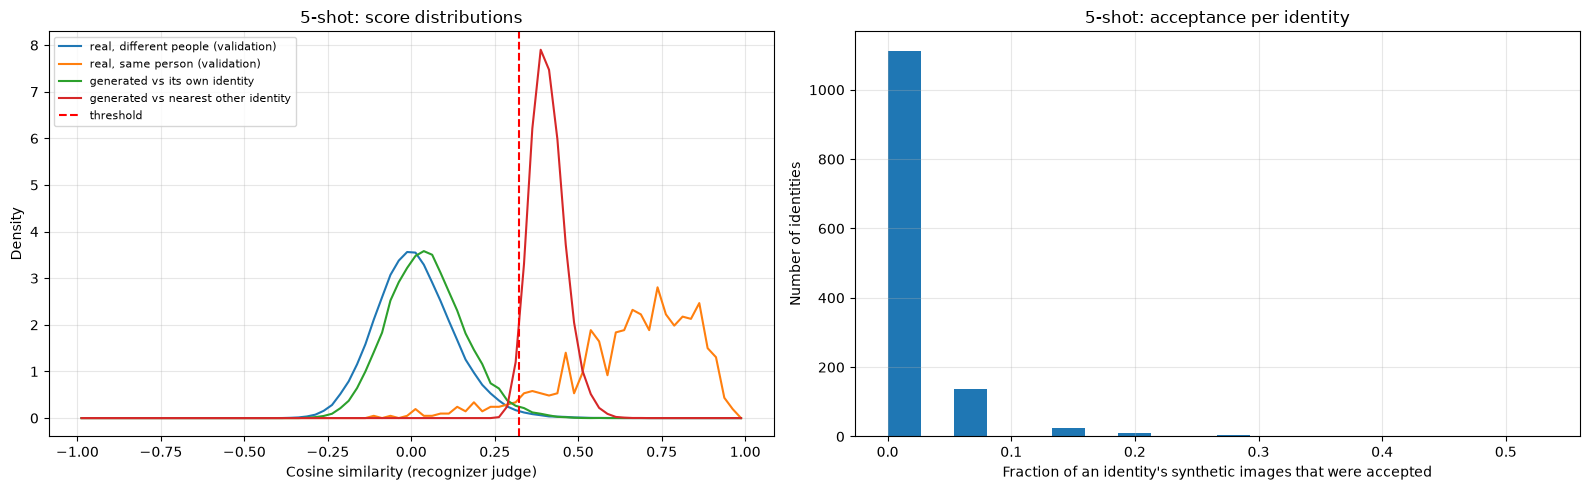

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\identity_verification\verification_scores_5shot.png


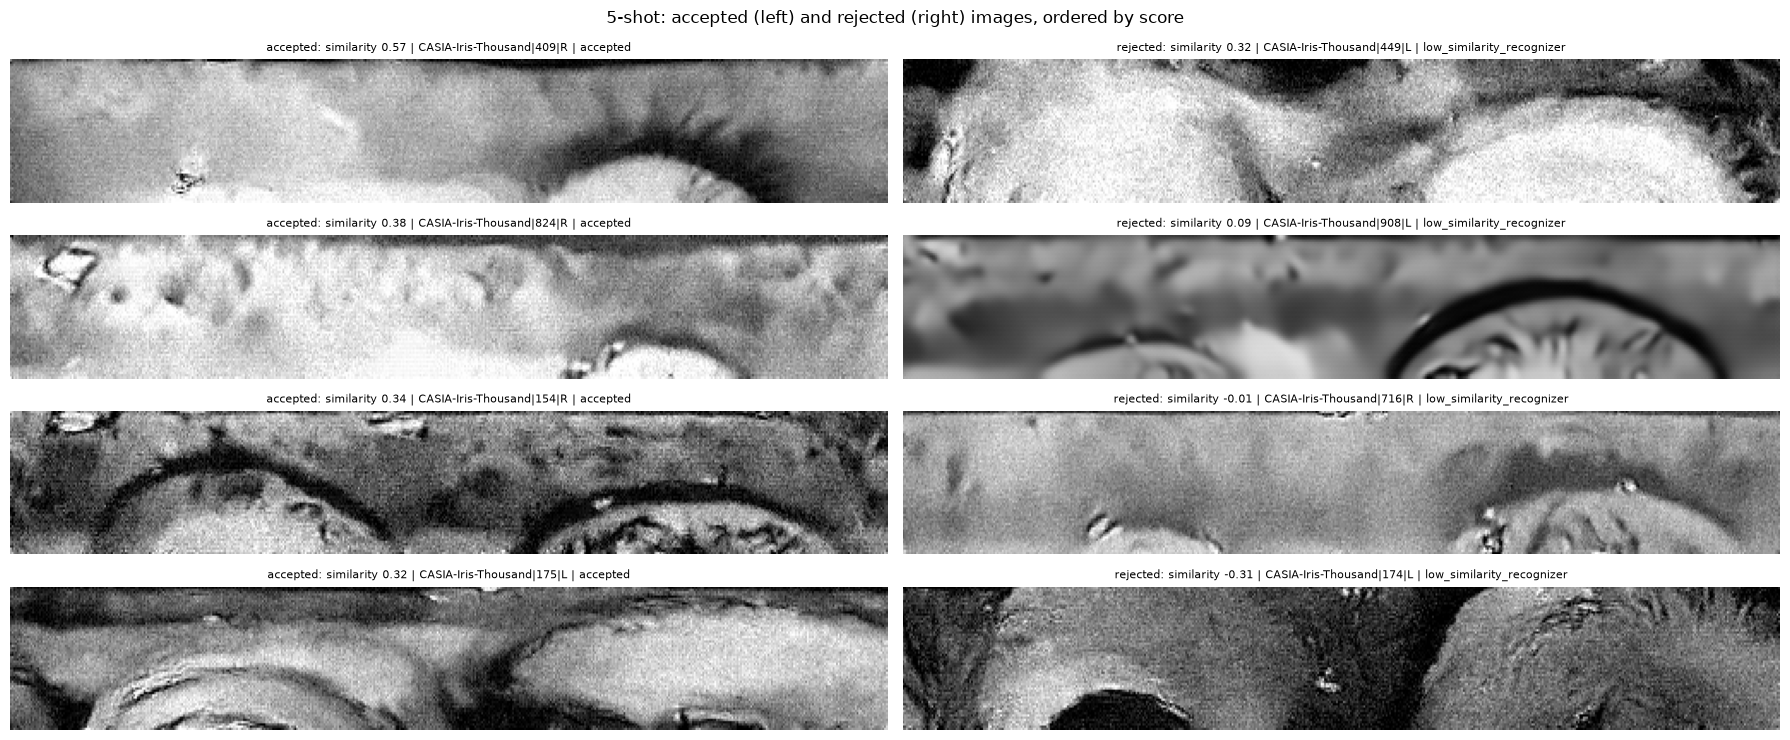

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\identity_verification\verification_examples_5shot.png


In [14]:
# ============================================================
# 13. Figures
# ============================================================

largest_shot = int(verification_scores["shot"].max())
record = next(r for r in full_records if r["shot"] == largest_shot)
judge_name = DECISION_JUDGES[0]
histograms = record["histograms"][judge_name]
centers = (HISTOGRAM_EDGES[:-1] + HISTOGRAM_EDGES[1:]) / 2.0
width = HISTOGRAM_EDGES[1] - HISTOGRAM_EDGES[0]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for key, label in [("val_impostor", "real, different people (validation)"),
                   ("val_genuine", "real, same person (validation)"),
                   ("generated_own", "generated vs its own identity"),
                   ("generated_other", "generated vs nearest other identity")]:
    counts = np.array(histograms.get(key, []), dtype=float)
    if counts.sum() > 0:
        axes[0].plot(centers, counts / counts.sum() / width, label=label)

axes[0].axvline(record["calibration"][judge_name]["threshold"], color="red", linestyle="--", label="threshold")
axes[0].set_xlabel(f"Cosine similarity ({judge_name} judge)")
axes[0].set_ylabel("Density")
axes[0].set_title(f"{largest_shot}-shot: score distributions")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

per_identity = identity_acceptance[identity_acceptance["shot"] == largest_shot]
axes[1].hist(per_identity["acceptance_rate"], bins=20, color="tab:blue")
axes[1].set_xlabel("Fraction of an identity's synthetic images that were accepted")
axes[1].set_ylabel("Number of identities")
axes[1].set_title(f"{largest_shot}-shot: acceptance per identity")
axes[1].grid(alpha=0.3)

plt.tight_layout()
histogram_path = RESULTS_DIR / f"verification_scores_{largest_shot}shot.png"
plt.savefig(histogram_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", histogram_path)

# ---- examples: accepted (left) and rejected (right) across the range of scores ----
score_column = f"sim_{judge_name}"
group = verification_scores[verification_scores["shot"] == largest_shot]
picks = {}
for label in ["accepted", "rejected"]:
    subset = group[group["accepted"] == (label == "accepted")].sort_values(score_column, ascending=False)
    picks[label] = subset.iloc[np.unique(np.linspace(0, len(subset) - 1, 4).round().astype(int))] if len(subset) else subset

fig, axes = plt.subplots(4, 2, figsize=(18, 7.5), squeeze=False)
for ax in axes.flatten():
    ax.axis("off")

for column, label in enumerate(["accepted", "rejected"]):
    for row, (_, item) in enumerate(picks[label].iterrows()):
        image = cv2.imread(str(SYNTHETIC_DIR / item["relative_path"]), cv2.IMREAD_GRAYSCALE)
        axes[row, column].imshow(image, cmap="gray", vmin=0, vmax=255, aspect="auto")
        axes[row, column].set_title(f"{label}: similarity {item[score_column]:.2f} | {item['class_id']} | {item['reason']}", fontsize=8)

plt.suptitle(f"{largest_shot}-shot: accepted (left) and rejected (right) images, ordered by score", fontsize=12)
plt.tight_layout()
examples_path = RESULTS_DIR / f"verification_examples_{largest_shot}shot.png"
plt.savefig(examples_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", examples_path)

## 14. Sanity checks

**Stop the notebook if:**
- a planned run is missing, or a leakage guard failed;
- the decisions are not exactly one per synthetic image of Notebook 10, or a `verify_id` repeats;
- accepted + rejected does not add up, or a threshold is not finite;
- the `accepted/` and `rejected/` folders do not contain exactly the images that were decided on.

**Warn if** (these describe expected behaviour, not guaranteed behaviour):
- fewer than 5% or more than 99.5% of the images are accepted (the filter either removes almost everything or almost nothing);
- more than 20% of the identities have too few accepted images;
- at the chosen threshold fewer than 20% of real same-person validation images pass (the judge is too weak to be useful);
- more than 1% of the images are degenerate.

In [15]:
# ============================================================
# 14. Sanity checks
# ============================================================

checks = []


def add_check(name, passed, details="", critical=True):
    checks.append({"check": name, "passed": bool(passed), "critical": critical, "details": details})
    status = "PASS" if passed else ("FAIL" if critical else "WARN")
    print(f"[{status}] {name}" + (f"  ({details})" if details else ""))


expected_ids = {make_run_id(shot) for shot in plan}
missing_runs = expected_ids - set(runs_table["run_id"])
add_check("all planned runs are present", not missing_runs, f"{len(missing_runs)} missing")
add_check("every run passed the leakage guards", bool(runs_table["leakage_checks_passed"].all()))

add_check("verify_id is unique", verification_scores["verify_id"].is_unique)

upstream = synthetic_manifest[synthetic_manifest["shot"].isin(plan)
                              & synthetic_manifest["generator_run_id"].isin(expected_ids)]
add_check("every synthetic image of Notebook 10 has exactly one decision",
          set(upstream["verify_id"]) == set(verification_scores["verify_id"]) and len(upstream) == len(verification_scores),
          f"{len(upstream)} synthetic images, {len(verification_scores)} decisions")

add_check("accepted + rejected equals the number of images",
          bool((runs_table["n_accepted"] + runs_table["n_rejected"] == runs_table["n_images"]).all()))

thresholds_ok = bool(np.isfinite(calibration_table["threshold"]).all())
add_check("every threshold is finite", thresholds_ok)

if PLACEMENT_MODE != "manifest_only":
    wrong_folders = []
    for _, run in runs_table.iterrows():
        n_accepted = sum(1 for _ in (ACCEPTED_DIR / run["run_id"]).rglob("*.png")) if (ACCEPTED_DIR / run["run_id"]).exists() else 0
        n_rejected = sum(1 for _ in (REJECTED_DIR / run["run_id"]).rglob("*.png")) if (REJECTED_DIR / run["run_id"]).exists() else 0
        if n_accepted != run["n_accepted"] or n_rejected != run["n_rejected"]:
            wrong_folders.append(run["run_id"])
    add_check("accepted/ and rejected/ contain exactly the images that were decided on", not wrong_folders,
              f"{len(wrong_folders)} run(s) differ")

    expected_paths = set(verification_scores["verified_path"])
    missing_links = [p for p in list(expected_paths)[:2000] if not (VERIFIED_DIR / p).exists()]
    add_check("the listed verified paths exist (checked on a sample)", not missing_links, f"{len(missing_links)} missing")

for _, run in runs_table.iterrows():
    rate = run["acceptance_rate"]
    add_check(f"{int(run['shot'])}-shot: acceptance rate is between 5% and 99.5%", 0.05 <= rate <= 0.995,
              f"{rate:.1%}", critical=False)

for shot, group in identity_acceptance.groupby("shot"):
    fraction = float(group["too_few_accepted"].mean())
    add_check(f"{int(shot)}-shot: at most 20% of the identities have too few accepted images", fraction <= 0.2,
              f"{fraction:.1%} of identities", critical=False)

for _, row in calibration_table[calibration_table["decides"]].iterrows():
    if "val_tar_at_threshold" in row and not pd.isna(row["val_tar_at_threshold"]):
        add_check(f"{int(row['shot'])}-shot / {row['judge']}: at least 20% of real same-person validation images pass the threshold",
                  row["val_tar_at_threshold"] >= 0.2, f"{row['val_tar_at_threshold']:.1%}", critical=False)

degenerate_fraction = verification_scores.groupby("shot")["degenerate"].mean()
for shot, fraction in degenerate_fraction.items():
    add_check(f"{int(shot)}-shot: fewer than 1% degenerate images", fraction < 0.01, f"{fraction:.2%}", critical=False)

sanity_report = pd.DataFrame(checks)
sanity_report.to_csv(RESULTS_DIR / "verification_sanity_checks.csv", index=False)
print("\nSaved:", RESULTS_DIR / "verification_sanity_checks.csv")

critical_failures = sanity_report[(~sanity_report["passed"]) & sanity_report["critical"]]
failed_names = list(critical_failures["check"])
assert len(critical_failures) == 0, f"Critical verification checks failed: {failed_names}"
print("\nVerification sanity checks completed with no critical failures.")

[PASS] all planned runs are present  (0 missing)
[PASS] every run passed the leakage guards
[PASS] verify_id is unique
[PASS] every synthetic image of Notebook 10 has exactly one decision  (94005 synthetic images, 94005 decisions)
[PASS] accepted + rejected equals the number of images
[PASS] every threshold is finite
[PASS] accepted/ and rejected/ contain exactly the images that were decided on  (0 run(s) differ)
[PASS] the listed verified paths exist (checked on a sample)  (0 missing)
[WARN] 1-shot: acceptance rate is between 5% and 99.5%  (1.3%)
[WARN] 2-shot: acceptance rate is between 5% and 99.5%  (1.3%)
[WARN] 3-shot: acceptance rate is between 5% and 99.5%  (1.5%)
[WARN] 5-shot: acceptance rate is between 5% and 99.5%  (1.4%)
[WARN] 1-shot: at most 20% of the identities have too few accepted images  (84.4% of identities)
[WARN] 2-shot: at most 20% of the identities have too few accepted images  (83.9% of identities)
[WARN] 3-shot: at most 20% of the identities have too few accep

## 15. Final outputs

At the end of Notebook 11, the project should contain:

```text
verified_images/
├── accepted/diffusion__<K>shot__seed<S>/<dataset>/<identity>_<eye>/syn_000.png ...
└── rejected/diffusion__<K>shot__seed<S>/<dataset>/<identity>_<eye>/syn_007.png ...

results/identity_verification/
├── verification_scores.csv            one row per synthetic image, every score and the decision
├── accepted_manifest.csv              what Notebook 13 reads
├── rejected_manifest.csv
├── identity_acceptance.csv
├── verification_runs.csv, verification_calibration.csv, verification_reasons.csv
├── verification_sanity_checks.csv
├── scores/<run_id>.csv                scores of one shot
├── runs/                              one JSON record per shot (thresholds, histograms)
└── verification_scores_<K>shot.png, verification_examples_<K>shot.png
```

The images in `accepted/` and `rejected/` are hard links (or copies) of the files in `generated_images/`, which stay untouched.

In [16]:
# ============================================================
# 15. Final output listing
# ============================================================

print("Verified images:", VERIFIED_DIR)
for base in (ACCEPTED_DIR, REJECTED_DIR):
    for run_dir in sorted(p for p in base.iterdir() if p.is_dir()):
        print(f"- {base.name}/{run_dir.name}/  ({sum(1 for _ in run_dir.rglob('*.png'))} images)")

print("\nNotebook 11 results:", RESULTS_DIR)
for path in sorted(RESULTS_DIR.iterdir()):
    if path.is_file():
        print(f"- {path.name}")

print(f"\nSynthetic images verified: {len(verification_scores)} | accepted: {int(verification_scores['accepted'].sum())}")
print("\nNotebook 11 completed.")

Verified images: E:\Research\LargeScale_Synthetic_Iris_Generation\verified_images
- accepted/diffusion__1shot__seed42/  (336 images)
- accepted/diffusion__2shot__seed42/  (320 images)
- accepted/diffusion__3shot__seed42/  (338 images)
- accepted/diffusion__5shot__seed42/  (267 images)
- rejected/diffusion__1shot__seed42/  (26074 images)
- rejected/diffusion__2shot__seed42/  (24592 images)
- rejected/diffusion__3shot__seed42/  (22935 images)
- rejected/diffusion__5shot__seed42/  (19143 images)

Notebook 11 results: E:\Research\LargeScale_Synthetic_Iris_Generation\results\identity_verification
- accepted_manifest.csv
- identity_acceptance.csv
- rejected_manifest.csv
- verification_calibration.csv
- verification_examples_5shot.png
- verification_reasons.csv
- verification_runs.csv
- verification_sanity_checks.csv
- verification_scores.csv
- verification_scores_5shot.png

Synthetic images verified: 94005 | accepted: 1261

Notebook 11 completed.


## 16. What this notebook hands to Notebooks 12 and 13

```text
Notebook 10                 Notebook 11                              Notebooks 12, 13
Synthetic images,   --->    Identity verification:           --->    12: diversity of the accepted images
manifest                    accepted / rejected + scores             13: train on real + accepted synthetic images
```

### The manifests

`results/identity_verification/accepted_manifest.csv` is the list of images that may be used for training. Per image it keeps everything from the Notebook 10 manifest, plus:

| Column | Meaning |
|---|---|
| `verify_id` | Unique ID (run, identity, index) |
| `sim_<judge>`, `other_<judge>`, `margin_<judge>` | Similarity to the own identity, to the nearest other identity, and their difference |
| `pass_<judge>`, `nearest_<judge>` | Whether the judge accepts the image, and whether the own identity is the nearest |
| `accepted`, `reason` | The decision and the first reason for rejection (`accepted` if none) |
| `relative_path`, `verified_path` | Path relative to `generated_images/`, and relative to `verified_images/` |

```python
accepted = pd.read_csv(RESULTS_DIR / "accepted_manifest.csv", dtype={"identity": str, "eye": str})
image = cv2.imread(str(PROJECT_ROOT / "generated_images" / accepted.loc[0, "relative_path"]), cv2.IMREAD_GRAYSCALE)
```

### How each later notebook uses it

| Notebook | Use |
|---|---|
| **12 Diversity** | Measure how varied the **accepted** images of one identity are, and compare them with the real ones. The filter prefers images that look like the real ones, so check that diversity did not collapse. |
| **13 Final recognition** | Train on the real `train / support` images plus the **accepted** synthetic images only (read the manifest, never glob the folders). Validation and test stay real. |
| **16 Ablations** | Different numbers of synthetic images per identity: take the first `m` accepted images per identity ordered by `synth_index`. Different identity thresholds: change `TARGET_FAR` here and re-run (only the decisions change; the images stay). |

### Rules that keep the no-leakage guarantee intact

1. Synthetic images belong to **training identities** and are used for **training only**. Validation and test stay real.
2. The threshold uses **real validation people only**. Do not tune `TARGET_FAR` on test results or on the unseen dataset.
3. Use the accepted images of the **same shot** as the experiment.
4. Do not edit or delete files in `generated_images/`; rejected images stay available for analysis.
5. Report `CONFIG_HASH`, the judges, the threshold rule, and the acceptance rate with every number that uses the filtered data.

### Reading the results

| What you see | Likely cause | What to try |
|---|---|---|
| Almost everything rejected | The generator is weak, or the judge is strict for the identities it was trained on | Look at the examples and histograms. If the images look good, relax `TARGET_FAR` (for example 0.05) |
| Almost everything accepted | The threshold is too low, or the judge cannot tell people apart | Check `val_tar_at_threshold` and `val_rank1` of the judge; lower `TARGET_FAR`; try `REQUIRE_NEAREST_IDENTITY = True` |
| The "generated vs own" curve sits on the "different people" curve | The generated images do not carry the identity | Improve the generator (Notebook 09) before filtering |
| Judges disagree often | They measure different things; the latent judge is correlated with the generator | Keep the recognizer as the decision judge; use `DECISION_JUDGES = ["recognizer", "latent"]` only if you want the stricter rule |
| Many identities with zero accepted images | Weak generation for those identities | Check their generated images; they train on real images only |